<a href="https://colab.research.google.com/github/saifuddin-vuia/saifuddin-vuia/blob/main/Statistics_CA_One.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assignment_CA.One_Task-1

In [7]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

Loading Dataset

In [9]:
df = pd.read_csv('/content/ecommerce_orders_clean.csv')

In [10]:
df.head()

,order_id,customer_id,product_id,category,price,quantity,order_date,shipping_date,delivery_status,payment_method,device_type,channel,shipping_address,billing_address,customer_segment
0,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,2031,845,Books,45.95,4,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,PayPal,Mobile,Paid Search,"976 Kevin Station, Davidmouth, Hawaii 92563","38182 Ariel Expressway, Campbellland, Oklahoma...",VIP
1,5ea92c47-c5b2-4bdd-8a50-d77efd77ec89,2350,995,Electronics,403.17,3,2024-04-20 14:59:58.897063,2024-04-22 14:59:58.897063,Delivered,PayPal,Mobile,Paid Search,"72166 Cunningham Crescent, East Nicholasside, ...","38199 Edwin Plain, Johnborough, Maine 81826",Returning
2,5cc48ce0-2c6d-4448-af3f-96f8a910d45b,1818,997,Beauty,317.45,2,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,Credit Card,Mobile,Email,"2446 Johnson Junctions, Lynchtown, Minnesota 7...","58086 Smith Stream Suite 994, Lake Pamelabury,...",Returning
3,74d5c0f4-53f0-4367-a5c5-baaa114c2d9f,472,385,Home,24.08,3,2024-04-20 14:59:58.897063,2024-04-24 14:59:58.897063,Shipped,PayPal,Tablet,Social,"3113 Jessica Knolls, North Joshuafort, Alabama...","484 Palmer Harbors Apt. 866, Dustintown, Nebra...",VIP
4,7a630323-8ac8-406e-875a-4bcdead440ab,1075,31,Clothing,494.90,1,2024-04-20 14:59:58.897063,2024-04-25 14:59:58.897063,Delivered,PayPal,Tablet,Organic,"58196 Burgess Heights Suite 315, Douglasland, ...","67094 Schaefer Villages Suite 369, Douglasches...",VIP


In [11]:
df.shape

(10000, 15)

Task_1(a) Describe the dataset using appropriate plots/curves/charts.  

In [ ]:
X = df['price'].dropna()

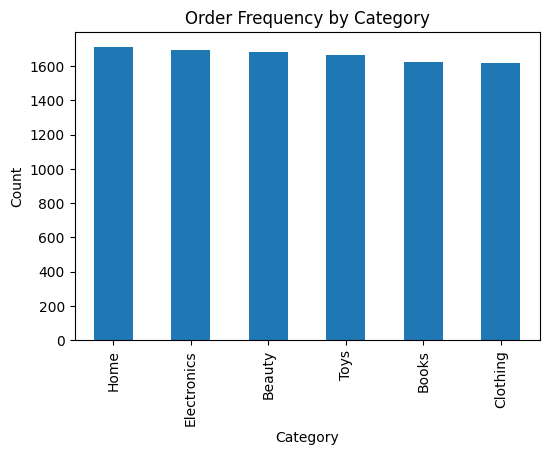

In [ ]:
# Bar plot for categorical variable (category)
plt.figure(figsize=(6, 4))
df['category'].value_counts().plot(kind='bar')
plt.title('Order Frequency by Category')
plt.xlabel('Category')
plt.ylabel('Count')
plt.show()

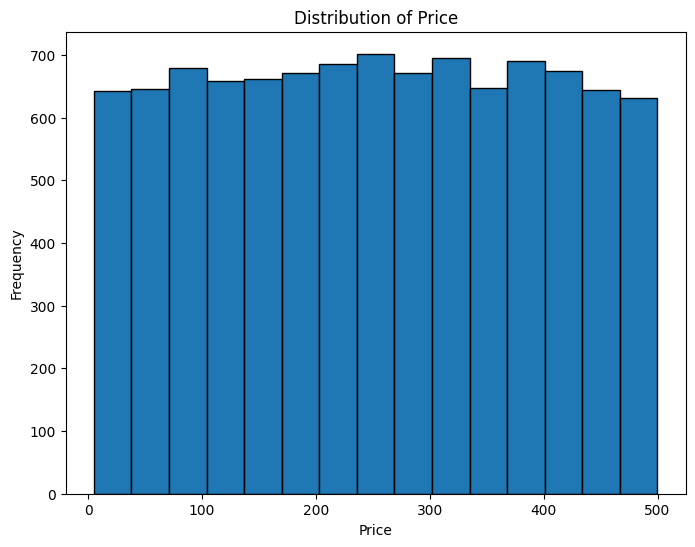

In [ ]:
# Histogram for continuous variable (price)
plt.figure(figsize=(8, 6))
plt.hist(X, bins=15, edgecolor='black')
plt.title('Distribution of Price')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

Task_1(b) Consider one of continuous variables and compute central and variational measures.

In [ ]:
# Central Tendency
mean_x = X.mean()
median_x = X.median()
mode_x = X.mode()[0]

# Variational Measures
range_x = X.max() - X.min()
var_x = X.var()
std_x = X.std()

print("Mean:", round(mean_x, 6))
print("Median:", round(median_x, 6))
print("Mode:", round(mode_x, 6))
print("Range:", round(range_x, 6))
print("Variance:", round(var_x, 6))
print("Standard Deviation:", round(std_x, 6))

Mean: 252.550681
Median: 252.91
Mode: 65.51
Range: 494.87
Variance: 19992.304511
Standard Deviation: 141.394146


Task_1(c) Chebyshev's Rule and One-Sigma Interval

In [ ]:
lower_sigma = mean_x - std_x
upper_sigma = mean_x + std_x

outside_sigma = X[(X < lower_sigma) | (X > upper_sigma)]
pct_outside = (len(outside_sigma) / len(X)) * 100

print(f"1-Sigma Interval: [{round(lower_sigma, 6)}, {round(upper_sigma, 6)}]")
print("Count outside 1-Sigma:", len(outside_sigma))
print("Percentage outside 1-Sigma:", round(pct_outside, 4), "%")

1-Sigma Interval: [111.156535, 393.944827]
Count outside 1-Sigma: 4212
Percentage outside 1-Sigma: 42.12 %


Task_1(d) Boxplot and IQR Outlier Detection

Q1 (25th Percentile): 130.6075
Q3 (75th Percentile): 374.9175
IQR: 244.31
Fences: [-235.8575, 741.3825]
Number of IQR Outliers: 0


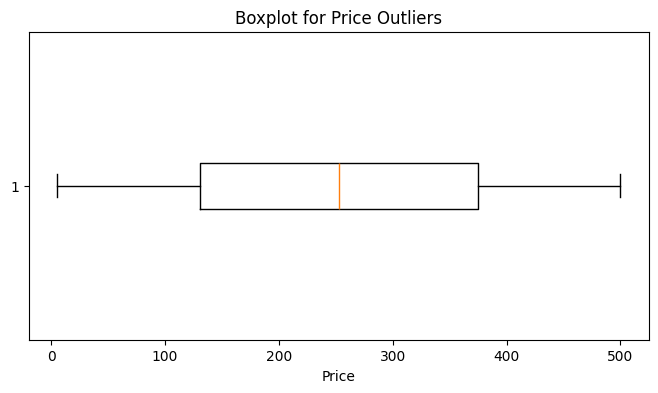

In [ ]:
# Quartiles and IQR
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outliers_iqr = X[(X < lower_fence) | (X > upper_fence)]

print("Q1 (25th Percentile):", round(q1, 6))
print("Q3 (75th Percentile):", round(q3, 6))
print("IQR:", round(iqr, 6))
print(f"Fences: [{round(lower_fence, 6)}, {round(upper_fence, 6)}]")
print("Number of IQR Outliers:", len(outliers_iqr))

# Boxplot
plt.figure(figsize=(8, 4))
plt.boxplot(X, vert=False)
plt.title('Boxplot for Price Outliers')
plt.xlabel('Price')
plt.show()

Task_2(a) Chi-Square Test of Independence ($\alpha = 0.01$)

In [ ]:
# i. Hypotheses & Contingency Table
# ii. Find Statistic and Critical Value
# iii. Decision & Result Interpretation

contingency = pd.crosstab(df['category'], df['delivery_status'])
alpha = 0.01


chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency)
critical_val = stats.chi2.ppf(1 - alpha, dof)

print('Contingency Table:')
print(contingency)
print('\nDegrees of Freedom (dof):', dof)
print('Calculated Chi2 Statistic:', round(chi2_stat, 6))
print('Critical Chi2 Value:', round(critical_val, 6))
print('p-value:', p_val)

if p_val < alpha:
  print(f'Decision: Reject H0 since p-value ({p_val:.6e}) < alpha ({alpha}).')
  print('Interpretation: There is a statistically significant association between Product Category and Delivery Status.')

else:
  print(f'Decision: Fail to Reject H0 since p-value ({p_val:.6f}) >= alpha ({alpha}).')
  print('Interpretation: Product Category and Delivery Status are independent.')

Contingency Table:
delivery_status  Delivered  Pending  Returned  Shipped
category                                              
Beauty                1185       87        89      321
Books                 1134       93        77      321
Clothing              1134       69        83      334
Electronics           1195       73        86      340
Home                  1217       95        87      314
Toys                  1182       96        80      308

Degrees of Freedom (dof): 15
Calculated Chi2 Statistic: 12.175873
Critical Chi2 Value: 30.577914
p-value: 0.6656709381121113
Decision: Fail to Reject H0 since p-value (0.665671) >= alpha (0.01).
Interpretation: Product Category and Delivery Status are independent.


Task_2(b) Chi-Square Goodness-of-Fit Test ($\alpha = 0.05$)

In [ ]:
obs_counts = df['delivery_status'].value_counts()
k = len(obs_counts)
alpha = 0.05

# Candidate set of equal probabilities
expected_counts = [len(df) / k] * k

chi2_gof, p_val_gof = stats.chisquare(f_obs=obs_counts, f_exp=expected_counts)
critical_val_gof = stats.chi2.ppf(1 - alpha, df=k - 1)

print('Observed Frequencies:')
print(obs_counts)
print('\nCalculated Chi2 Statistic:', round(chi2_gof, 6))
print('Critical Value:', round(critical_val_gof, 6))
print('p-value:', p_val_gof)

if p_val_gof < alpha:
  print(f'Decision: Reject H0 since p-value ({p_val_gof:.6e}) < alpha ({alpha}).')
  print('Interpretation: Observed class frequencies do not follow the proposed candidate distribution.')

else:
  print(f'Decision: Fail to Reject H0 since p-value ({p_val_gof:.6f}) >= alpha ({alpha}).')
  print('Interpretation: The proposed candidate probabilities fit the observed class frequencies well.')

Observed Frequencies:
delivery_status
Delivered    7047
Shipped      1938
Pending       513
Returned      502
Name: count, dtype: int64

Calculated Chi2 Statistic: 11572.4904
Critical Value: 7.814728
p-value: 0.0
Decision: Reject H0 since p-value (0.000000e+00) < alpha (0.05).
Interpretation: Observed class frequencies do not follow the proposed candidate distribution.


Task_2(c)  One-Sample Test of Mean ($\alpha = 0.05$)

In [ ]:
price = df['price'].dropna()
alpha = 0.05
mu_0 = 100.0

t_stat, p_val_mean = stats.ttest_1samp(price, popmean=mu_0)

print('Sample Mean:', round(price.mean(), 6))
print('Hypothesized Candidate Mean (mu_0):', mu_0)
print('t-statistic:', round(t_stat, 6))
print('p-value:', p_val_mean)

if p_val_mean < alpha:
  print(f'Decision: Reject H0 since p-value ({p_val_mean:.4e}) < alpha ({alpha}).')
  print(f'Interpretation: The population mean price is statistically significantly different from {mu_0}.')

else:
  print(f'Decision: Fail to Reject H0 since p-value ({p_val_mean:.6f}) >= alpha ({alpha}).')
  print(f'Interpretation: There is no statistically significant difference between the true mean price and {mu_0}.')

Sample Mean: 252.550681
Hypothesized Candidate Mean (mu_0): 100.0
t-statistic: 107.89038
p-value: 0.0
Decision: Reject H0 since p-value (0.0000e+00) < alpha (0.05).
Interpretation: The population mean price is statistically significantly different from 100.0.


Task_3(a,b)  Parameter Estimation for 4 Variables

In [12]:
# 1. Continuous Variable 1: price
price = df['price'].dropna()
a_price, b_price = price.min(), price.max()
mu_price, std_price = price.mean(), price.std()

# 2. Continuous Variable 2: quantity
quantity = df['quantity'].dropna()
lambda_qty = quantity.mean()

# 3. Categorical Variable 1: delivery_status
status_props = df['delivery_status'].value_counts(normalize=True)

# 4. Categorical Variable 2: category
cat_props = df['category'].value_counts(normalize=True)

print(f'1. Price (Uniform/Normal): Min={a_price:.4f}, Max={b_price:.4f}, Mean={mu_price:.4f}, Std={std_price:.4f}')
print(f'2. Quantity (Poisson Lambda): {lambda_qty:.6f}')
print(f'3. Delivery Status Probabilities:\n', round(status_props, 6))
print('\n4. Category Probabilities:\n', round(cat_props, 6))

1. Price (Uniform/Normal): Min=5.0600, Max=499.9300, Mean=252.5507, Std=141.3941
2. Quantity (Poisson Lambda): 2.124700
3. Delivery Status Probabilities:
 delivery_status
Delivered    0.7047
Shipped      0.1938
Pending      0.0513
Returned     0.0502
Name: proportion, dtype: float64

4. Category Probabilities:
 category
Home           0.1713
Electronics    0.1694
Beauty         0.1682
Toys           0.1666
Books          0.1625
Clothing       0.1620
Name: proportion, dtype: float64


Task_3(c)

In [15]:
# App 1: Probability price > 300
p_price_300 = 1 - stats.norm.cdf(300, loc=mu_price, scale=std_price)

# App 2: Probability quantity > 3
p_qty_3 = 1 - stats.poisson.cdf(3, mu=lambda_qty)

# App 3: Probability of getting exactly 8 delivered out of 10 orders
p_deliv = status_props['Delivered']
p_8_deliv = stats.binom.pmf(8, n=10, p=p_deliv)

# App 4: Probability that two consecutive orders are Electronics
p_elec = cat_props['Electronics']
p_2_elec = p_elec ** 2

# Print the final results
print("App 1 - P(Price > 300):", round(p_price_300, 6))
print("App 2 - P(Quantity > 3):", round(p_qty_3, 6))
print("App 3 - P(8 Delivered in 10 Orders):", round(p_8_deliv, 6))
print("App 4 - P(2 Consecutive Electronics):", round(p_2_elec, 6))

App 1 - P(Price > 300): 0.368593
App 2 - P(Quantity > 3): 0.16605
App 3 - P(8 Delivered in 10 Orders): 0.238657
App 4 - P(2 Consecutive Electronics): 0.028696
